<center><h1>Test Batting Explorer – Python Analysis</h1></center>
<center><h3>Software Laboratory – Group Mini Project</h3></center>

### Group Members : 1. Aadesh Thakre-25      2. Anurag Somwanshi-29     3. Avadhoot Tiwaskar-31
### Section : A5          Batch : B2
### Tools used : Python, Pandas, NumPy, Matplotlib, Seaborn

### -------------------------------------------------------------------------------------------------------------

## Problem Statement
We have the career Test batting records of 3,001 cricketers (up to 2019) in a CSV file. In this project we use Python to **clean** the data, **calculate** new columns, find the **top players** in different categories, compare **countries and decades**, and show the results with **charts**.

| Column | Meaning |
|---|---|
| `name`, `country`, `span` | Player name, country code, years played |
| `mat`, `inn`, `no` | Matches, innings, not-outs |
| `runs`, `hs`, `avg` | Career runs, highest score, batting average |
| `h`, `f`, `d` | Hundreds, fifties, ducks |
| `career_yrs`, `category`, `debut_decade` | Career length, player category (by runs), decade of first Test |

## Step 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)     # show all the columns when printing
pd.set_option("display.width", 200)

df = pd.read_csv("test_batting.csv")

print("Shape of the data:", df.shape)
print()
print("Data types:")
print(df.dtypes)

Shape of the data: (3001, 16)

Data types:
name             object
country          object
span             object
mat               int64
inn               int64
no                int64
runs              int64
hs               object
hs_num          float64
avg             float64
h                 int64
f                 int64
d                 int64
career_yrs        int64
category         object
debut_decade      int64
dtype: object


In [2]:
print("First 5 rows:")
print(df.head())
print()
print("Last 5 rows:")
print(df.tail())

First 5 rows:
           name country       span  mat  inn  no   runs    hs  hs_num    avg   h   f   d  career_yrs category  debut_decade
0  SR Tendulkar   INDIA  1989-2013  200  329  33  15921  248*   248.0  53.78  51  68  14          24   Legend          1980
1    RT Ponting     AUS  1995-2012  168  287  29  13378   257   257.0  51.85  41  62  17          17   Legend          1990
2     JH Kallis      SA  1995-2013  166  280  40  13289   224   224.0  55.37  45  58  16          18   Legend          1990
3      R Dravid   INDIA  1996-2012  164  286  32  13288   270   270.0  52.31  36  63   8          16   Legend          1990
4       AN Cook     ENG  2006-2018  161  291  16  12472   294   294.0  45.35  33  57   9          12   Legend          2000

Last 5 rows:
                name country       span  mat  inn  no  runs   hs  hs_num  avg  h  f  d  career_yrs category  debut_decade
2996      CA Snedden      NZ  1947-1947    1    0   0     0  NaN     NaN  NaN  0  0  0           0   Fring

**Observation:** The data has 3,001 rows (players) and 16 columns.

## Step 2. Check for missing values

In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
name             0
country          0
span             0
mat              0
inn              0
no               0
runs             0
hs              20
hs_num          20
avg             88
h                0
f                0
d                0
career_yrs       0
category         0
debut_decade     0
dtype: int64


**Observation:** `avg` is missing for players who were never dismissed, and `hs` / `hs_num` are missing for players who never batted. These are real cases (not mistakes), so we keep them as NaN. Pandas skips NaN automatically while calculating mean, max and sort.

## Step 3. Add new columns

#### 3.1 Replace country codes with full country names

In [4]:
names = {"ENG": "England", "AUS": "Australia", "INDIA": "India", "WI": "West Indies",
         "SA": "South Africa", "PAK": "Pakistan", "NZ": "New Zealand", "SL": "Sri Lanka",
         "BDESH": "Bangladesh", "ZIM": "Zimbabwe", "AFG": "Afghanistan", "IRE": "Ireland"}

df["country_name"] = df["country"].replace(names)

print(df[["name", "country", "country_name"]].head())

           name country  country_name
0  SR Tendulkar   INDIA         India
1    RT Ponting     AUS     Australia
2     JH Kallis      SA  South Africa
3      R Dravid   INDIA         India
4       AN Cook     ENG       England


#### 3.2 Runs per match and century conversion

In [5]:
# runs scored per match played
df["runs_per_match"] = df["runs"] / df["mat"]

# century conversion = hundreds as a percentage of all scores of 50 or more
df["conversion"] = df["h"] / (df["h"] + df["f"]) * 100

print(df[["name", "runs", "mat", "runs_per_match", "h", "f", "conversion"]].head())

           name   runs  mat  runs_per_match   h   f  conversion
0  SR Tendulkar  15921  200       79.605000  51  68   42.857143
1    RT Ponting  13378  168       79.630952  41  62   39.805825
2     JH Kallis  13289  166       80.054217  45  58   43.689320
3      R Dravid  13288  164       81.024390  36  63   36.363636
4       AN Cook  12472  161       77.465839  33  57   36.666667


#### 3.3 Qualified players

In [6]:
# averages are not reliable for players with very few runs,
# so for averages and rates we only use players with 1000 or more runs
qualified = df[df["runs"] >= 1000]

print("Players in the data:", len(df))
print("Qualified players (1000+ runs):", len(qualified))

Players in the data: 3001
Qualified players (1000+ runs): 549


## Step 4. Basic statistics

In [7]:
cols = ["mat", "inn", "runs", "avg", "h", "f", "d"]
df[cols].describe().round(2)

,mat,inn,runs,avg,h,f,d
count,3001.00,3001.00,3001.00,2913.00,3001.00,3001.00,3001.00
mean,17.43,28.09,740.05,20.54,1.40,3.39,3.03
std,24.95,40.65,1553.17,14.55,4.25,7.64,4.25
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,4.00,36.00,9.50,0.00,0.00,0.00
50%,7.00,11.00,155.00,18.00,0.00,0.00,1.00
75%,21.00,34.00,663.00,29.15,1.00,3.00,4.00
max,200.00,329.00,15921.00,160.50,51.00,68.00,43.00


In [8]:
print("Total runs scored by all players:", df["runs"].sum())
print("Total hundreds scored:", df["h"].sum())
print("Average of the batting averages (qualified):", round(qualified["avg"].mean(), 2))
print("Median of the batting averages (qualified):", round(qualified["avg"].median(), 2))
print()
print("Number of players in each category:")
print(df["category"].value_counts())

Total runs scored by all players: 2220876
Total hundreds scored: 4197
Average of the batting averages (qualified): 36.15
Median of the batting averages (qualified): 35.72

Number of players in each category:
category
Fringe         2124
Regular         564
Established     217
Great            66
Legend           30
Name: count, dtype: int64


**Observation:** Most players (2,124) are in the `Fringe` category with under 500 runs, and only 30 players are `Legend`s with 8,000+ runs.

## Step 5. Top players
We write one small function and reuse it for every list. It sorts the data by a column (highest first) and returns the top `n` rows.

In [9]:
def top_players(column, n=10, only_qualified=False):
    data = df
    if only_qualified:
        data = qualified                       # use only the players with 1000+ runs

    result = data.sort_values(by=column, ascending=False).head(n)

    show = ["name", "country_name", "span", "mat", "runs"]
    if column not in show:
        show.append(column)                    # add the sorted column at the end

    result = result[show]
    result.index = range(1, len(result) + 1)   # rank 1, 2, 3 ...
    return result

#### 5.1 Most runs

In [10]:
top_players("runs")

,name,country_name,span,mat,runs
1,SR Tendulkar,India,1989-2013,200,15921
2,RT Ponting,Australia,1995-2012,168,13378
3,JH Kallis,South Africa,1995-2013,166,13289
4,R Dravid,India,1996-2012,164,13288
5,AN Cook,England,2006-2018,161,12472
6,KC Sangakkara,Sri Lanka,2000-2015,134,12400
7,BC Lara,West Indies,1990-2006,131,11953
8,S Chanderpaul,West Indies,1994-2015,164,11867
9,DPMD Jayawardene,Sri Lanka,1997-2014,149,11814
10,AR Border,Australia,1978-1994,156,11174


#### 5.2 Highest batting average (1000+ runs)

In [11]:
top_players("avg", only_qualified=True).round(2)

,name,country_name,span,mat,runs,avg
1,DG Bradman,Australia,1928-1948,52,6996,99.94
2,SG Barnes,Australia,1938-1948,13,1072,63.05
3,SPD Smith,Australia,2010-2019,72,7164,62.84
4,AC Voges,Australia,2015-2016,20,1485,61.87
5,RG Pollock,South Africa,1963-1970,23,2256,60.97
6,GA Headley,West Indies,1930-1954,22,2190,60.83
7,H Sutcliffe,England,1924-1935,54,4555,60.73
8,E Paynter,England,1931-1939,20,1540,59.23
9,KF Barrington,England,1955-1968,82,6806,58.67
10,ED Weekes,West Indies,1948-1958,48,4455,58.61


#### 5.3 Most hundreds

In [12]:
top_players("h")

,name,country_name,span,mat,runs,h
1,SR Tendulkar,India,1989-2013,200,15921,51
2,JH Kallis,South Africa,1995-2013,166,13289,45
3,RT Ponting,Australia,1995-2012,168,13378,41
4,KC Sangakkara,Sri Lanka,2000-2015,134,12400,38
5,R Dravid,India,1996-2012,164,13288,36
6,DPMD Jayawardene,Sri Lanka,1997-2014,149,11814,34
7,Younis Khan,Pakistan,2000-2017,118,10099,34
8,SM Gavaskar,India,1971-1987,125,10122,34
9,BC Lara,West Indies,1990-2006,131,11953,34
10,AN Cook,England,2006-2018,161,12472,33


#### 5.4 Most fifties

In [13]:
top_players("f", 5)

,name,country_name,span,mat,runs,f
1,SR Tendulkar,India,1989-2013,200,15921,68
2,S Chanderpaul,West Indies,1994-2015,164,11867,66
3,AR Border,Australia,1978-1994,156,11174,63
4,R Dravid,India,1996-2012,164,13288,63
5,RT Ponting,Australia,1995-2012,168,13378,62


#### 5.5 Most ducks

In [14]:
top_players("d", 5)

,name,country_name,span,mat,runs,d
1,CA Walsh,West Indies,1984-2001,132,936,43
2,CS Martin,New Zealand,2000-2013,71,123,36
3,GD McGrath,Australia,1993-2007,124,641,35
4,SCJ Broad,England,2007-2019,135,3158,35
5,SK Warne,Australia,1992-2007,145,3154,34


#### 5.6 Highest runs per match (1000+ runs)

In [15]:
top_players("runs_per_match", 5, only_qualified=True).round(2)

,name,country_name,span,mat,runs,runs_per_match
1,DG Bradman,Australia,1928-1948,52,6996,134.54
2,GA Headley,West Indies,1930-1954,22,2190,99.55
3,SPD Smith,Australia,2010-2019,72,7164,99.50
4,RG Pollock,South Africa,1963-1970,23,2256,98.09
5,ED Weekes,West Indies,1948-1958,48,4455,92.81


#### 5.7 Best century conversion (1000+ runs and at least 10 hundreds)

In [16]:
good = qualified[qualified["h"] >= 10]
best = good.sort_values(by="conversion", ascending=False).head(5)
best[["name", "country_name", "h", "f", "conversion"]].round(1)

,name,country_name,h,f,conversion
52,DG Bradman,Australia,29,13,69.0
283,GA Headley,West Indies,10,5,66.7
45,V Kohli,India,27,22,55.1
144,CL Walcott,West Indies,15,14,51.7
63,M Azharuddin,India,22,21,51.2


#### 5.8 Try your own – change the column name and run again

In [17]:
top_players("inn", 5)             

,name,country_name,span,mat,runs,inn
1,SR Tendulkar,India,1989-2013,200,15921,329
2,AN Cook,England,2006-2018,161,12472,291
3,RT Ponting,Australia,1995-2012,168,13378,287
4,R Dravid,India,1996-2012,164,13288,286
5,JH Kallis,South Africa,1995-2013,166,13289,280


**Observation:** Tendulkar leads in runs, hundreds and fifties. Bradman is far ahead in batting average (99.94), runs per match and century conversion, but he played only 52 matches. Courtney Walsh has the most ducks, which is expected for a bowler who batted at the end.

## Step 6. Compare countries, categories and decades

#### 6.1 Total runs and number of players of each country

In [18]:
country_runs = df.groupby("country_name")["runs"].sum().sort_values(ascending=False)
country_players = df.groupby("country_name")["name"].count()

summary = pd.DataFrame({"Players": country_players, "Total Runs": country_runs})
summary = summary.sort_values(by="Total Runs", ascending=False)
summary

,Players,Total Runs
country_name,,
England,690,468575
Australia,458,411271
India,295,258551
West Indies,319,255403
South Africa,339,202908
Pakistan,237,197604
New Zealand,277,190941
Sri Lanka,150,136780
Bangladesh,95,50120


#### 6.2 Average of the batting averages for each country (qualified players)

In [19]:
country_avg = qualified.groupby("country_name")["avg"].mean().sort_values(ascending=False)
country_avg.round(2)

country_name
Australia       38.63
West Indies     37.51
South Africa    37.26
England         37.16
India           35.03
Pakistan        34.97
Sri Lanka       33.83
New Zealand     33.70
Zimbabwe        31.17
Bangladesh      29.38
Name: avg, dtype: float64

#### 6.3 Total runs and hundreds in each debut decade

In [20]:
decade_runs = df.groupby("debut_decade")["runs"].sum()
decade_hundreds = df.groupby("debut_decade")["h"].sum()

decade_table = pd.DataFrame({"Runs": decade_runs, "Hundreds": decade_hundreds})
decade_table

,Runs,Hundreds
debut_decade,,
1870,7063,5
1880,21253,24
1890,39201,59
1900,37471,64
1910,14191,18
1920,77348,165
1930,73480,150
1940,74254,146
1950,167847,293


**Observation:** England and Australia have scored the most runs. The 1990s and 2000s debut decades have the highest run totals. The 2010s total is lower partly because the data ends in 2019, so those careers are not finished yet. Australia has the highest average among qualified players (38.6).

## Step 7. Correlation

In [21]:
corr = df[cols].corr().round(2)
corr

,mat,inn,runs,avg,h,f,d
mat,1.00,0.99,0.88,0.39,0.75,0.83,0.81
inn,0.99,1.00,0.92,0.43,0.80,0.88,0.78
runs,0.88,0.92,1.00,0.54,0.95,0.97,0.54
avg,0.39,0.43,0.54,1.00,0.52,0.55,0.12
h,0.75,0.80,0.95,0.52,1.00,0.89,0.42
f,0.83,0.88,0.97,0.55,0.89,1.00,0.49
d,0.81,0.78,0.54,0.12,0.42,0.49,1.00


In [22]:
print("Correlation between runs and hundreds:", round(df["runs"].corr(df["h"]), 2))
print("Correlation between matches and batting average:", round(df["mat"].corr(df["avg"]), 2))

Correlation between runs and hundreds: 0.95
Correlation between matches and batting average: 0.39


**Observation:** Runs and hundreds have a very strong positive correlation (0.95). Matches played and batting average have only a weak relation (0.39), so playing more matches does not mean a better average.

## Step 8. Data visualization

#### 8.1 Bar chart – top 10 run scorers

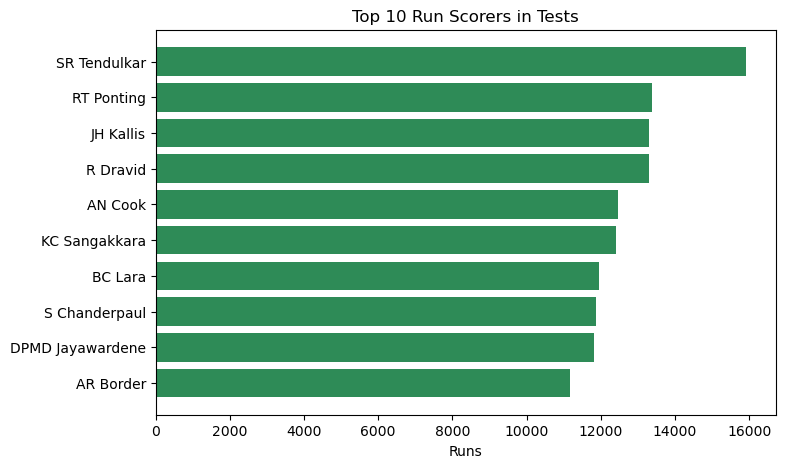

In [23]:
top10 = top_players("runs", 10)

plt.figure(figsize=(8, 5))
plt.barh(top10["name"], top10["runs"], color="seagreen")
plt.gca().invert_yaxis()                    # so that rank 1 is at the top
plt.title("Top 10 Run Scorers in Tests")
plt.xlabel("Runs")
plt.show()

#### 8.2 Bar chart – total runs of each country

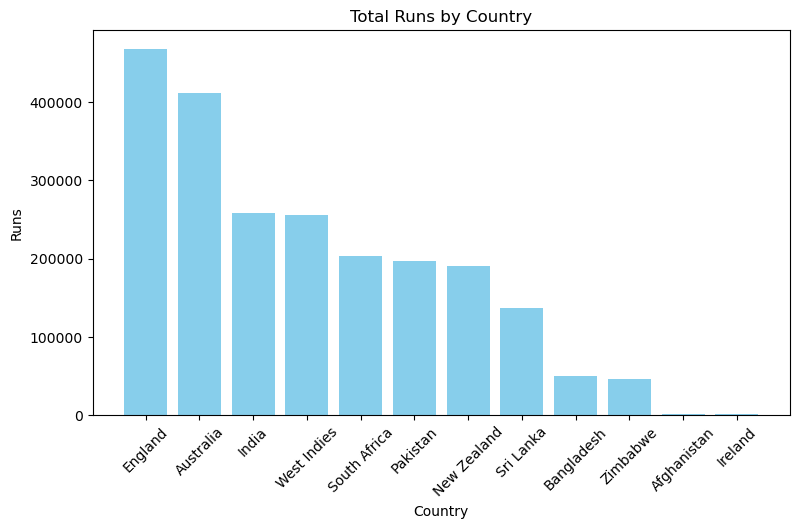

In [24]:
plt.figure(figsize=(9, 5))
plt.bar(country_runs.index, country_runs.values, color="skyblue")
plt.title("Total Runs by Country")
plt.xlabel("Country")
plt.ylabel("Runs")
plt.xticks(rotation=45)
plt.show()

#### 8.3 Pie chart – countries of the top 10 run scorers

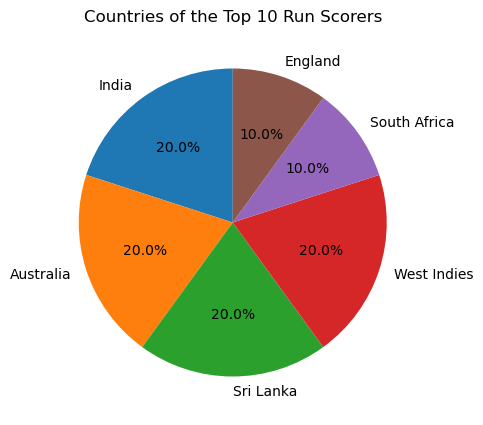

In [25]:
counts = top10["country_name"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Countries of the Top 10 Run Scorers")
plt.show()

#### 8.4 Line chart – total runs in each debut decade

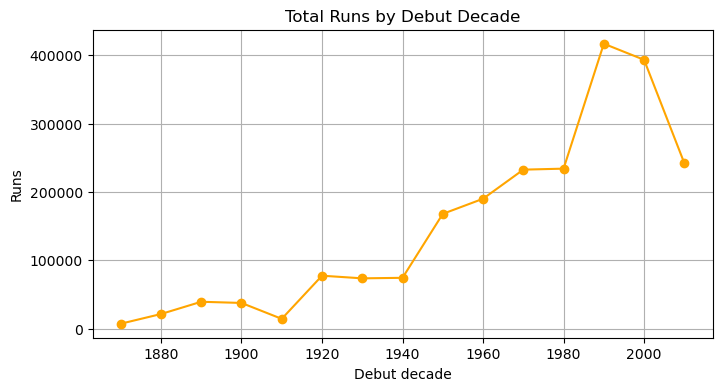

In [26]:
plt.figure(figsize=(8, 4))
plt.plot(decade_runs.index, decade_runs.values, marker="o", color="orange")
plt.title("Total Runs by Debut Decade")
plt.xlabel("Debut decade")
plt.ylabel("Runs")
plt.grid(True)
plt.show()

#### 8.5 Scatter plot – matches played vs runs

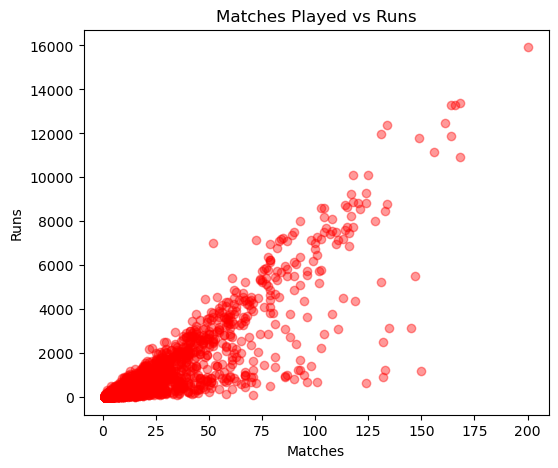

In [27]:
plt.figure(figsize=(6, 5))
plt.scatter(df["mat"], df["runs"], color="red", alpha=0.4)
plt.title("Matches Played vs Runs")
plt.xlabel("Matches")
plt.ylabel("Runs")
plt.show()

#### 8.6 Histogram – batting averages of qualified players

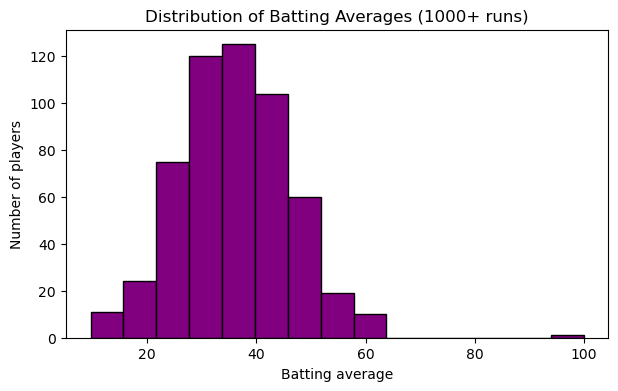

In [28]:
plt.figure(figsize=(7, 4))
plt.hist(qualified["avg"], bins=15, color="purple", edgecolor="black")
plt.title("Distribution of Batting Averages (1000+ runs)")
plt.xlabel("Batting average")
plt.ylabel("Number of players")
plt.show()

#### 8.7 Seaborn – number of players in each category

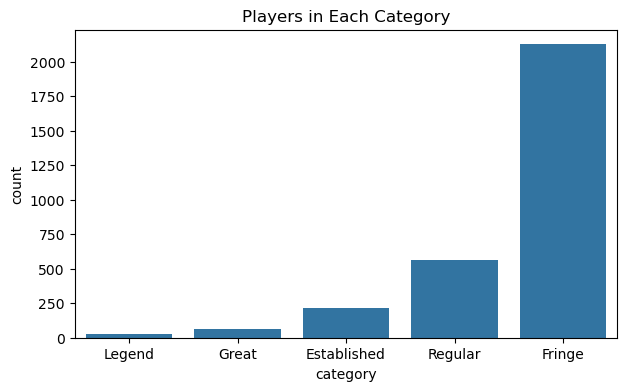

In [29]:
plt.figure(figsize=(7, 4))
sns.countplot(x="category", data=df, order=["Legend", "Great", "Established", "Regular", "Fringe"])
plt.title("Players in Each Category")
plt.show()

#### 8.8 Seaborn – box plot of batting averages for each country

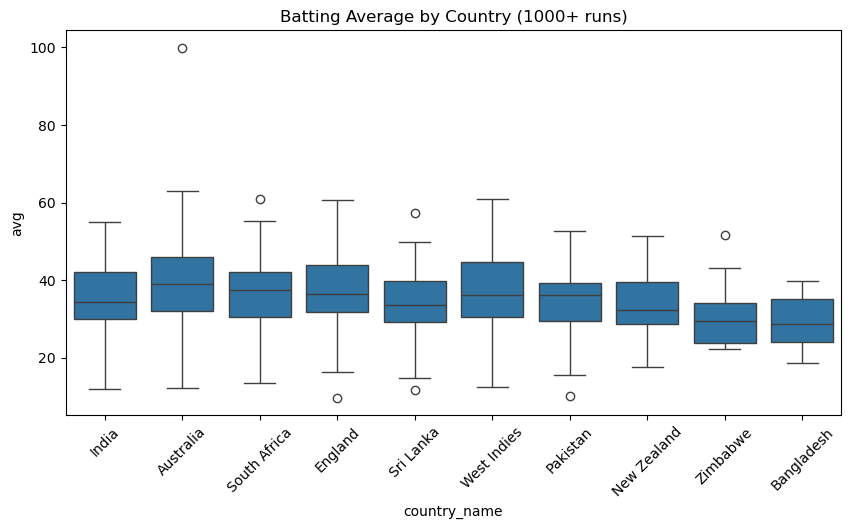

In [30]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="country_name", y="avg", data=qualified)
plt.xticks(rotation=45)
plt.title("Batting Average by Country (1000+ runs)")
plt.show()

#### 8.9 Seaborn – heatmap of the correlation matrix

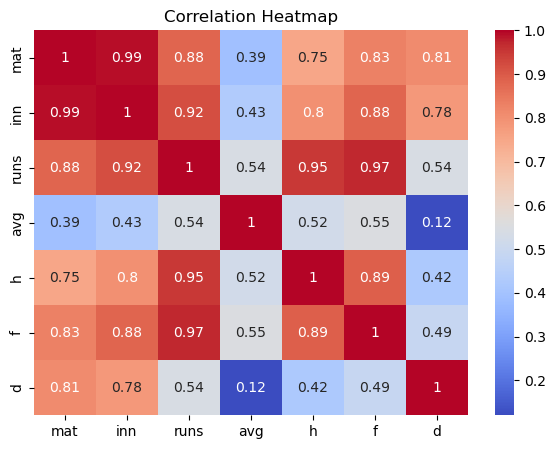

In [31]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Observation:** The bar charts compare players and countries, the line chart shows how runs changed over decades, the scatter plot shows that more matches generally means more runs, and the histogram shows that more than half of the qualified players (about 57%) have an average between 30 and 45.

## Step 9. Save the results

In [32]:
df.to_csv("test_batting_clean.csv", index=False)
print("Saved test_batting_clean.csv with", len(df), "rows")

Saved test_batting_clean.csv with 3001 rows


## Conclusion
Using Python we loaded and cleaned the Test batting records, added new columns (country name, runs per match, century conversion), built a reusable `top_players()` function for the leaderboards, compared countries and decades with `groupby`, studied correlations, and presented the findings with Matplotlib and Seaborn charts. Tendulkar is the top scorer in Tests, while Bradman has by far the highest average.

# ----------------------------------------//---------------------------------------------------